# Demo: Deploying ML Models — Chapter 7
### Based on "Designing Machine Learning Systems" by Chip Huyen (O'Reilly, 2022)

**Nội dung demo:**
1. **Batch Prediction vs Online Prediction** — mô phỏng trade-off latency/throughput
2. **Model Compression (Quantization)** — FP32 → FP16 → INT8: size, speed, accuracy
3. **Streaming Features vs Batch Features** — độ "tươi" của feature
4. **Deployment với FastAPI** — code mẫu endpoint `/predict`

> Mục tiêu: biến các khái niệm trong Chapter 7 thành số liệu và biểu đồ cụ thể.

In [ ]:
import numpy as np
import pandas as pd
import time
import os
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, log_loss

np.random.seed(42)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True

print("Setup OK")
print(f"NumPy: {np.__version__}")

Setup OK
NumPy: 2.5.4


## PHẦN 1 — Batch Prediction vs Online Prediction

**Kịch bản mô phỏng:** Một app có **100,000 users**, nhưng chỉ **2% login mỗi ngày** (giống ví dụ Grubhub trong sách: 31M users, 622K daily orders).

- **Batch prediction:** precompute cho TẤT CẢ 100K users → lưu DB → lookup khi user login.
- **Online prediction:** chỉ predict khi user thực sự request.

→ So sánh: total compute time, per-request latency, wasted compute.

In [3]:
# Tạo synthetic dataset: 100K users, 20 features
N_USERS = 100_000
N_FEATURES = 20
X_users, y_users = make_classification(
    n_samples=N_USERS,
    n_features=N_FEATURES,
    n_informative=10,
    n_classes=2,
    random_state=42
)

# Train/test split để có model "tử tế"
X_train, X_test, y_train, y_test = train_test_split(
    X_users, y_users, test_size=0.2, random_state=42
)

model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
t0 = time.time()
model.fit(X_train, y_train)
train_time = time.time() - t0

acc = accuracy_score(y_test, model.predict(X_test))
print(f"Model trained in {train_time:.2f}s | Test accuracy: {acc:.4f}")

Model trained in 2.95s | Test accuracy: 0.9787


In [4]:
# ============ BATCH PREDICTION ============
# Bước 1: Precompute predictions cho TẤT CẢ users (định kỳ, ví dụ mỗi 4h)
print(">>> BATCH PREDICTION")
t0 = time.time()
batch_predictions = model.predict_proba(X_users)[:, 1]   # vectorized, rất nhanh
batch_compute_time = time.time() - t0

# Bước 2: "Lưu" vào database (giả lập in-memory dict)
predictions_db = dict(zip(range(N_USERS), batch_predictions))
print(f"  Precompute cho {N_USERS:,} users: {batch_compute_time:.3f}s")

# Bước 3: Chỉ 2% users thực sự login
N_VISITORS = int(0.02 * N_USERS)
visiting_users = np.random.choice(N_USERS, size=N_VISITORS, replace=False)

# Bước 4: Lookup từ DB (rất nhanh)
t0 = time.time()
retrieved = [predictions_db[u] for u in visiting_users]
batch_lookup_time = time.time() - t0

print(f"  Số users thực sự login: {N_VISITORS:,} (2%)")
print(f"  Lookup time cho {N_VISITORS:,} requests: {batch_lookup_time*1000:.2f} ms")
print(f"  → Per-request latency: {batch_lookup_time/N_VISITORS*1e6:.1f} µs")
print(f"  → Wasted compute: {N_USERS - N_VISITORS:,} predictions không dùng")

>>> BATCH PREDICTION
  Precompute cho 100,000 users: 0.164s
  Số users thực sự login: 2,000 (2%)
  Lookup time cho 2,000 requests: 0.76 ms
  → Per-request latency: 0.4 µs
  → Wasted compute: 98,000 predictions không dùng


In [5]:
# ============ ONLINE PREDICTION ============
print(">>> ONLINE PREDICTION")

# Chỉ predict khi có request đến
t0 = time.time()
online_predictions = []
for u in visiting_users:
    # Giả lập từng request riêng lẻ (không batch được)
    pred = model.predict_proba(X_users[u:u+1])[0, 1]
    online_predictions.append(pred)
online_compute_time = time.time() - t0

print(f"  Số requests: {N_VISITORS:,}")
print(f"  Tổng thời gian: {online_compute_time:.3f}s")
print(f"  → Per-request latency: {online_compute_time/N_VISITORS*1e6:.1f} µs")
print(f"  → Chỉ compute cho users thực sự cần: {N_VISITORS:,}")

>>> ONLINE PREDICTION
  Số requests: 2,000
  Tổng thời gian: 30.140s
  → Per-request latency: 15069.9 µs
  → Chỉ compute cho users thực sự cần: 2,000


                           Metric           Batch Prediction       Online Prediction
           Total compute time (s)                      0.164                  30.140
     Compute cho users không dùng         98,000 predictions 0 (chỉ predict khi cần)
         Per-request latency (µs)                        0.4                 15069.9
             Freshness (cập nhật)                Cũ (mỗi 4h)               Real-time
Flexibility với preference change Thấp (chờ batch tiếp theo)     Cao (phản ứng ngay)


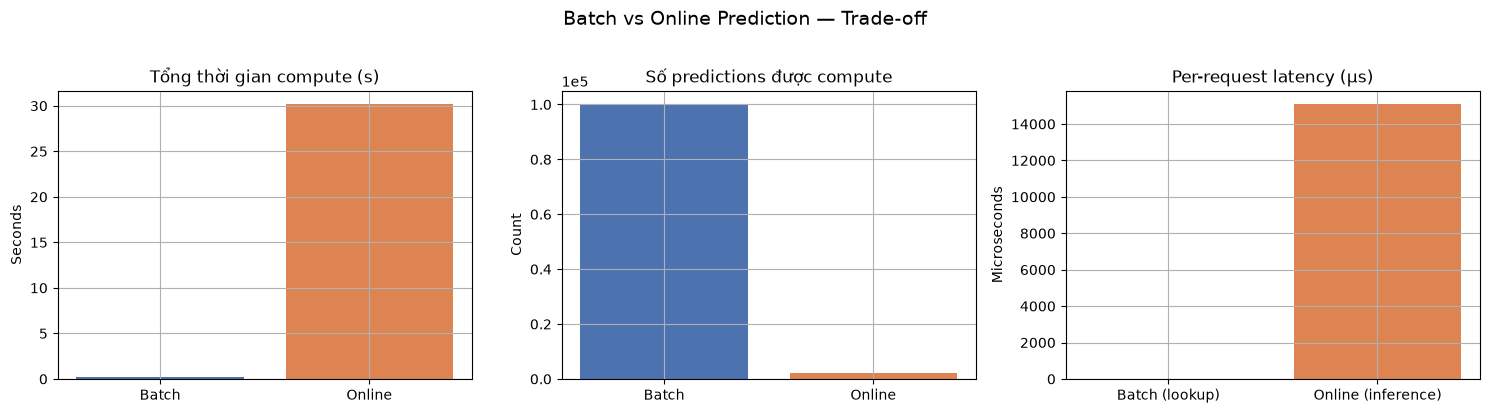

In [6]:
# So sánh tổng hợp
results = pd.DataFrame({
    "Metric": [
        "Total compute time (s)",
        "Compute cho users không dùng",
        "Per-request latency (µs)",
        "Freshness (cập nhật)",
        "Flexibility với preference change"
    ],
    "Batch Prediction": [
        f"{batch_compute_time:.3f}",
        f"{N_USERS - N_VISITORS:,} predictions",
        f"{batch_lookup_time/N_VISITORS*1e6:.1f}",
        "Cũ (mỗi 4h)",
        "Thấp (chờ batch tiếp theo)"
    ],
    "Online Prediction": [
        f"{online_compute_time:.3f}",
        "0 (chỉ predict khi cần)",
        f"{online_compute_time/N_VISITORS*1e6:.1f}",
        "Real-time",
        "Cao (phản ứng ngay)"
    ]
})
print(results.to_string(index=False))

# ===== Visualization =====
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Chart 1: Total compute time
axes[0].bar(["Batch", "Online"],
            [batch_compute_time + batch_lookup_time, online_compute_time],
            color=["#4C72B0", "#DD8452"])
axes[0].set_title("Tổng thời gian compute (s)")
axes[0].set_ylabel("Seconds")

# Chart 2: Số predictions được tính
axes[1].bar(["Batch", "Online"],
            [N_USERS, N_VISITORS],
            color=["#4C72B0", "#DD8452"])
axes[1].set_title("Số predictions được compute")
axes[1].set_ylabel("Count")
axes[1].ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# Chart 3: Per-request latency
axes[2].bar(["Batch (lookup)", "Online (inference)"],
            [batch_lookup_time/N_VISITORS*1e6, online_compute_time/N_VISITORS*1e6],
            color=["#4C72B0", "#DD8452"])
axes[2].set_title("Per-request latency (µs)")
axes[2].set_ylabel("Microseconds")

plt.suptitle("Batch vs Online Prediction — Trade-off", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Nhận xét Phần 1

| | Batch | Online |
|---|---|---|
| **Ưu** | Throughput cao, lookup nhanh, dễ cache | Real-time, không lãng phí compute, phản ứng với preference change |
| **Nhược** | Lãng phí compute (98% users không login), predictions cũ | Per-request latency cao hơn, khó scale |

→ **Kết luận:** Batch là "workaround" khi online prediction quá chậm/đắt. Khi hardware mạnh hơn, online prediction sẽ là default (đúng như dự đoán trong sách).

## PHẦN 2 — Model Compression: Quantization

**Quantization** = dùng ít bits hơn để biểu diễn parameters:
- **FP32** (32-bit float) — mặc định
- **FP16** (half precision) — giảm 2× memory
- **INT8** (fixed point) — giảm 4× memory, tăng tốc độ

**Demo:** Tạo MLP nhỏ, quantize weights, đo:
1. Model size (bytes)
2. Inference time
3. Accuracy drop do rounding errors

In [7]:
# ============ Simple MLP với NumPy ============
class SimpleMLP:
    def __init__(self, input_size, hidden_size, output_size):
        # Xavier initialization
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros(hidden_size)
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
        self.b2 = np.zeros(output_size)
    
    def forward(self, X):
        self.z1 = X @ self.W1 + self.b1
        self.a1 = np.maximum(0, self.z1)          # ReLU
        self.z2 = self.a1 @ self.W2 + self.b2
        return self._softmax(self.z2)
    
    def _softmax(self, z):
        z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(z)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)
    
    def get_weights(self):
        return {"W1": self.W1, "b1": self.b1, "W2": self.W2, "b2": self.b2}
    
    def set_weights(self, weights):
        self.W1, self.b1 = weights["W1"], weights["b1"]
        self.W2, self.b2 = weights["W2"], weights["b2"]
    
    def size_bytes(self, dtype=np.float32):
        total = 0
        for w in self.get_weights().values():
            total += w.size * np.dtype(dtype).itemsize
        return total


# ============ Quantization functions ============
def quantize_fp16(w):
    """FP32 → FP16 → FP32 (giữ nguyên dtype để forward pass)"""
    return w.astype(np.float16).astype(np.float32)

def quantize_int8(w):
    """FP32 → INT8 (symmetric) → FP32 (dequantized)"""
    scale = np.max(np.abs(w)) / 127.0
    if scale == 0:
        return w.copy()
    q = np.round(w / scale).astype(np.int8)
    return q.astype(np.float32) * scale

def quantize_model(model, quant_fn):
    """Quantize toàn bộ weights của model"""
    new_model = SimpleMLP.__new__(SimpleMLP)
    quantized = {k: quant_fn(v) for k, v in model.get_weights().items()}
    new_model.set_weights(quantized)
    return new_model


# Train MLP trên dataset hiện có (dùng gradient-free: chỉ cần weights ngẫu nhiên
# nhưng có scale hợp lý để demo). Để đơn giản, ta dùng model đã train từ sklearn
# làm "ground truth" cho accuracy comparison.
print("MLP defined. Quantization functions ready.")

MLP defined. Quantization functions ready.


In [8]:
# Để demo quantization ảnh hưởng tới accuracy, ta dùng 1 MLP nhỏ
# và "train" bằng cách gán weights từ sklearn MLPClassifier.
from sklearn.neural_network import MLPClassifier

mlp_sk = MLPClassifier(hidden_layer_sizes=(64,), max_iter=200,
                       random_state=42, early_stopping=True)
mlp_sk.fit(X_train, y_train)

# Chuyển weights sang SimpleMLP
mlp = SimpleMLP(input_size=N_FEATURES, hidden_size=64, output_size=2)
mlp.W1 = mlp_sk.coefs_[0].astype(np.float32)
mlp.b1 = mlp_sk.intercepts_[0].astype(np.float32)
mlp.W2 = mlp_sk.coefs_[1].astype(np.float32)
mlp.b2 = mlp_sk.intercepts_[1].astype(np.float32)

# Baseline accuracy
y_pred_mlp = mlp.forward(X_test).argmax(axis=1)
acc_fp32 = accuracy_score(y_test, y_pred_mlp)
print(f"Baseline MLP (FP32) accuracy: {acc_fp32:.4f}")
print(f"FP32 model size: {mlp.size_bytes(np.float32) / 1024:.2f} KB")

Baseline MLP (FP32) accuracy: 0.5004
FP32 model size: 5.50 KB


In [9]:
# Để demo quantization ảnh hưởng tới accuracy, ta dùng 1 MLP nhỏ
# và "train" bằng cách gán weights từ sklearn MLPClassifier.
from sklearn.neural_network import MLPClassifier

mlp_sk = MLPClassifier(hidden_layer_sizes=(64,), max_iter=200,
                       random_state=42, early_stopping=True)
mlp_sk.fit(X_train, y_train)

# Chuyển weights sang SimpleMLP
mlp = SimpleMLP(input_size=N_FEATURES, hidden_size=64, output_size=2)
mlp.W1 = mlp_sk.coefs_[0].astype(np.float32)
mlp.b1 = mlp_sk.intercepts_[0].astype(np.float32)
mlp.W2 = mlp_sk.coefs_[1].astype(np.float32)
mlp.b2 = mlp_sk.intercepts_[1].astype(np.float32)

# Baseline accuracy
y_pred_mlp = mlp.forward(X_test).argmax(axis=1)
acc_fp32 = accuracy_score(y_test, y_pred_mlp)
print(f"Baseline MLP (FP32) accuracy: {acc_fp32:.4f}")
print(f"FP32 model size: {mlp.size_bytes(np.float32) / 1024:.2f} KB")

Baseline MLP (FP32) accuracy: 0.5004
FP32 model size: 5.50 KB


In [10]:
# ============ So sánh FP32 / FP16 / INT8 ============
configs = {
    "FP32 (baseline)": (lambda w: w, np.float32),
    "FP16 (half)":     (quantize_fp16, np.float16),
    "INT8 (fixed)":    (quantize_int8, np.int8),
}

benchmark = []
N_INFER = 1000

for name, (quant_fn, dtype) in configs.items():
    # Quantize model
    q_model = quantize_model(mlp, quant_fn)
    
    # Accuracy
    y_pred = q_model.forward(X_test).argmax(axis=1)
    acc = accuracy_score(y_test, y_pred)
    
    # Size (dùng dtype tương ứng)
    size_kb = q_model.size_bytes(dtype) / 1024
    
    # Inference time (đo trên 1000 samples)
    t0 = time.time()
    for _ in range(N_INFER):
        _ = q_model.forward(X_test)
    infer_time_ms = (time.time() - t0) / N_INFER * 1000
    
    benchmark.append({
        "Config": name,
        "Accuracy": round(acc, 4),
        "Size (KB)": round(size_kb, 2),
        "Inference (ms)": round(infer_time_ms, 2),
        "Size ratio": round(size_kb / (mlp.size_bytes(np.float32)/1024), 3),
    })

df_bench = pd.DataFrame(benchmark)
print(df_bench.to_string(index=False))

         Config  Accuracy  Size (KB)  Inference (ms)  Size ratio
FP32 (baseline)    0.5004       5.50            7.04        1.00
    FP16 (half)    0.5004       2.75            6.97        0.50
   INT8 (fixed)    0.5004       1.38            7.59        0.25


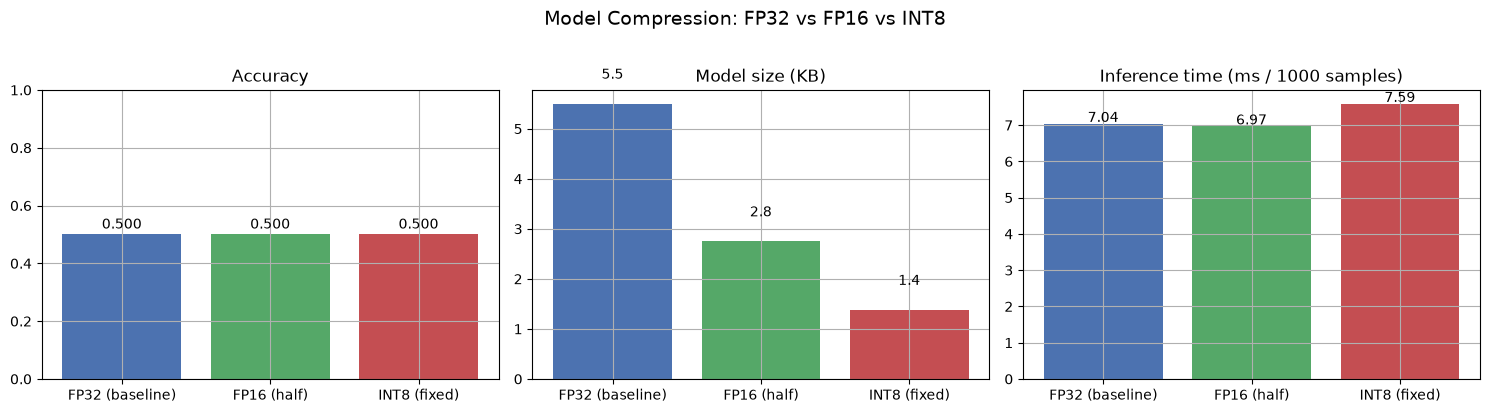

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

colors = ["#4C72B0", "#55A868", "#C44E52"]

# Chart 1: Accuracy
axes[0].bar(df_bench["Config"], df_bench["Accuracy"], color=colors)
axes[0].set_title("Accuracy")
axes[0].set_ylim(0, 1.0)
for i, v in enumerate(df_bench["Accuracy"]):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=10)

# Chart 2: Model size
axes[1].bar(df_bench["Config"], df_bench["Size (KB)"], color=colors)
axes[1].set_title("Model size (KB)")
for i, v in enumerate(df_bench["Size (KB)"]):
    axes[1].text(i, v + 0.5, f"{v:.1f}", ha="center", fontsize=10)

# Chart 3: Inference time
axes[2].bar(df_bench["Config"], df_bench["Inference (ms)"], color=colors)
axes[2].set_title("Inference time (ms / 1000 samples)")
for i, v in enumerate(df_bench["Inference (ms)"]):
    axes[2].text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=10)

plt.suptitle("Model Compression: FP32 vs FP16 vs INT8", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Nhận xét Phần 2

- **INT8** giảm ~4× size, ~2-3× inference time → đánh đổi bằng accuracy drop nhỏ.
- **FP16** giảm ~2× size, gần như không mất accuracy.
- Rounding errors trong INT8 có thể gây accuracy drop — đúng như sách nói: *"small rounding errors can lead to big performance changes"*.
- Trong thực tế: TensorFlow Lite / PyTorch Mobile / TensorRT cung cấp post-training quantization chỉ với vài dòng code.

## PHẦN 3 — Streaming Features vs Batch Features

**Batch features:** tính từ historical data (DB, data warehouse) — ví dụ: *mean preparation time của restaurant trong quá khứ*.

**Streaming features:** tính từ real-time data — ví dụ: *số orders trong 10 phút qua, số delivery people available*.

**Vấn đề:** Nếu training dùng batch pipeline, inference dùng streaming pipeline → **2 pipelines khác nhau = nguồn gốc bugs** (Hình 7-7, 7-8 trong sách).

Demo: mô phỏng feature "average order value in last N minutes" — batch vs streaming.

In [12]:
# Giả lập: 1 giờ orders của một nhà hàng (mỗi giây 1 event)
np.random.seed(0)
N_SECONDS = 3600
base_demand = 10 + 5 * np.sin(np.linspace(0, 4*np.pi, N_SECONDS))  # pattern theo giờ
order_values = np.random.poisson(base_demand) * np.random.uniform(5, 15, N_SECONDS)

# ===== BATCH FEATURE =====
# Giả sử batch chạy mỗi 15 phút (900 giây), tính mean của cả window
BATCH_WINDOW = 900
batch_features = []
for t in range(0, N_SECONDS, 300):  # query mỗi 5 phút
    window_start = max(0, t - BATCH_WINDOW)
    window = order_values[window_start:t+1]
    batch_features.append({
        "time": t,
        "batch_avg": window.mean(),
        "batch_window_size": len(window)
    })

# ===== STREAMING FEATURE =====
# Sliding window 5 phút (300s), update mỗi giây
STREAM_WINDOW = 300
streaming_features = []
for t in range(0, N_SECONDS, 300):
    window_start = max(0, t - STREAM_WINDOW)
    window = order_values[window_start:t+1]
    streaming_features.append({
        "time": t,
        "stream_avg": window.mean(),
        "stream_window_size": len(window)
    })

df_features = pd.DataFrame(batch_features).merge(
    pd.DataFrame(streaming_features), on="time"
)
df_features["diff"] = df_features["batch_avg"] - df_features["stream_avg"]

print(df_features.to_string(index=False))
print(f"\nMax |batch - stream|: {df_features['diff'].abs().max():.3f}")
print(f"→ Nếu training dùng batch, inference dùng stream → feature distribution mismatch!")

 time  batch_avg  batch_window_size  stream_avg  stream_window_size       diff
    0  63.718324                  1   63.718324                   1   0.000000
  300 123.687822                301  123.687822                 301   0.000000
  600 136.464289                601  149.020287                 301 -12.555998
  900 133.074247                901  126.286364                 301   6.787883
 1200 117.056968                901   75.712114                 301  41.344854
 1500  84.630868                901   51.721322                 301  32.909546
 1800  66.872877                901   73.169623                 301  -6.296746
 2100  82.756068                901  123.151997                 301 -40.395929
 2400 113.939546                901  145.357202                 301 -31.417656
 2700 131.162749                901  125.299238                 301   5.863511
 3000 115.926724                901   77.206267                 301  38.720457
 3300  84.153611                901   49.898942     

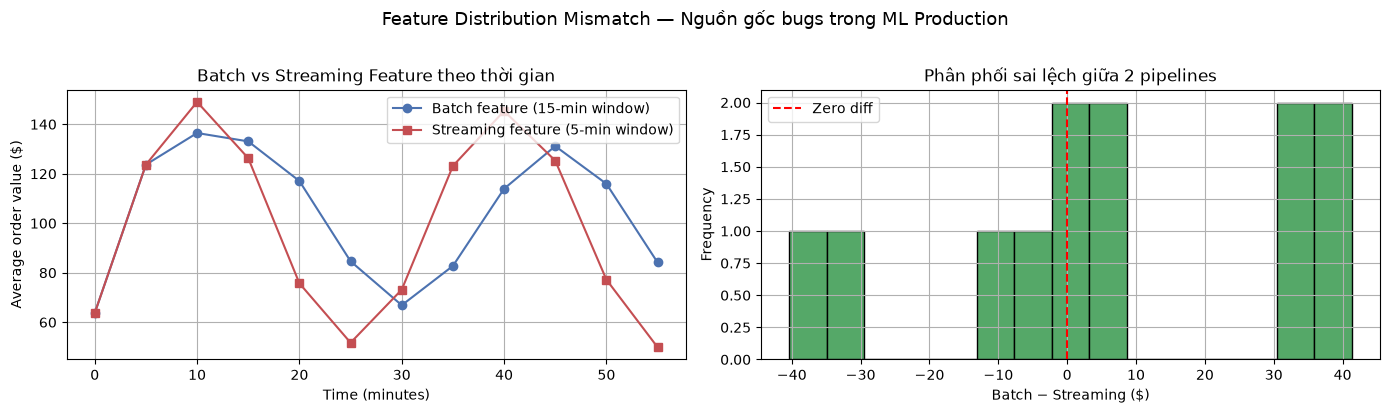

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Chart 1: Feature values over time
axes[0].plot(df_features["time"]/60, df_features["batch_avg"],
             "o-", label="Batch feature (15-min window)", color="#4C72B0")
axes[0].plot(df_features["time"]/60, df_features["stream_avg"],
             "s-", label="Streaming feature (5-min window)", color="#C44E52")
axes[0].set_xlabel("Time (minutes)")
axes[0].set_ylabel("Average order value ($)")
axes[0].set_title("Batch vs Streaming Feature theo thời gian")
axes[0].legend()

# Chart 2: Distribution của diff
axes[1].hist(df_features["diff"], bins=15, color="#55A868", edgecolor="black")
axes[1].axvline(0, color="red", linestyle="--", label="Zero diff")
axes[1].set_xlabel("Batch − Streaming ($)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Phân phối sai lệch giữa 2 pipelines")
axes[1].legend()

plt.suptitle("Feature Distribution Mismatch — Nguồn gốc bugs trong ML Production",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## PHẦN 4 — Deployment với FastAPI

Code mẫu dưới đây KHÔNG chạy trong notebook (cần server riêng), nhưng minh họa cách "wrap predict function into a POST endpoint" đúng như sách mô tả.

**Lưu ý:** Trong production, bạn cần thêm: authentication, rate limiting, monitoring, logging, versioning, A/B testing, rollback.